# Mosquito Species from Wingbeat Sound: Model Notebook

**Problem.** Malaria is still one of the biggest causes of illness in East Africa, and it is spread only by *Anopheles* mosquitoes. Knowing which species are flying in an area tells health workers where to put bed nets and spraying. Right now this is done by catching mosquitoes and identifying them under a microscope, which needs a trained entomologist. A flying mosquito makes a buzz whose pitch and overtones depend on its species, so a cheap recorder could do part of this job.

This project classifies a short recording into four classes:

| Class | What it is | Malaria vector? |
|---|---|---|
| *An. arabiensis* | main malaria vector in dry savanna areas | yes |
| *An. funestus* | major malaria vector, often indoors | yes |
| *Culex pipiens* complex | nuisance mosquito, spreads other diseases | no |
| Background | no mosquito, just room and recorder noise | no |

**Data.** HumBugDB (Kiskin et al., NeurIPS 2021 Datasets track, Zenodo record 4904800, CC BY 4.0). I only use recordings made in Tanzania with the same method (a mosquito in a cup, recorded with a Tascam recorder at 44.1 kHz, females only). If every class came from a different place or device, the model could learn the recorder instead of the insect.

**Notebook outline:** setup, data, preprocessing, feature interpretation, model, training, evaluation, prediction, retraining, conclusion.

## 1. Setup

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.model import SEED, augment, build_model, evaluate_model, evaluate_probabilities, list_clips, make_dataset
from src.preprocessing import (CLASSES, F_MAX, F_MIN, FREQUENCIES, BAND, HANN, HOP, INPUT_SHAPE, N_FFT, SAMPLE_RATE,
                               WINDOW, load_audio, log_spectrogram, split_windows, wingbeat_frequency)

DATA, MODELS = ROOT / "data", ROOT / "models"
MODEL_PATH, BASELINE_PATH = MODELS / "wingbeat_model.keras", MODELS / "baseline_model.keras"
NAMES = {"an_arabiensis": "An. arabiensis", "an_funestus": "An. funestus", "culex_pipiens": "Culex", "background": "Background"}
COLORS = {"an_arabiensis": "#2a78d6", "an_funestus": "#eb6834", "culex_pipiens": "#1baf7a", "background": "#eda100"}
RUN_FULL_TRAINING = False
tf.keras.utils.set_random_seed(SEED)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 2. Data acquisition

HumBugDB is about 4 GB, so the raw zips are not part of the repository. `scripts/prepare_data.py` downloads them once, selects the recordings described above and writes 2 second clips to `data/`.

**How the split works.** Recordings made on the same night share the same cup, room and background noise. If clips from one night appeared in both training and test, the model could score well by recognising the night. So each class is split by recording date: every night belongs to exactly one of train, validation or test. This makes the task harder, but the test score is closer to what would happen on a new recording.

Each class has 900 training, 200 validation and 200 test clips, so the classes are balanced in every split.

In [2]:
if not (DATA / "train").is_dir():
    print("Run: python scripts/prepare_data.py   (downloads HumBugDB and writes data/)")

manifest = pd.read_csv(DATA / "manifest.csv")
counts = manifest.pivot_table(index="label", columns="split", values="file", aggfunc="count")[["train", "validation", "test"]]
recordings = manifest.drop_duplicates("recording_id").pivot_table(index="label", columns="split", values="file", aggfunc="count")
nights = manifest.drop_duplicates(["label", "session"]).pivot_table(index="label", columns="split", values="file", aggfunc="count")
table = pd.concat({"clips": counts, "recordings": recordings[["train", "validation", "test"]],
                   "nights": nights[["train", "validation", "test"]]}, axis=1).rename(index=NAMES)
display(table)

clips                 recordings                 nights  \
split          train validation test      train validation test  train   
label                                                                    
An. arabiensis   900        200  200        446        101   87     32   
An. funestus     900        200  200        267         53   50     19   
Background       900        200  200         63         12   16     29   
Culex            900        200  200        361         58   52     26   

                                
split          validation test  
label                           
An. arabiensis          5    2  
An. funestus            5    6  
Background              7    6  
Culex                   4    6

### Data quality checks

In [3]:
shared = 0
for label, group in manifest.groupby("label"):
    sessions = {split: set(group[group.split == split].session) for split in ("train", "validation", "test")}
    shared += len(sessions["train"] & sessions["test"]) + len(sessions["train"] & sessions["validation"]) + len(sessions["validation"] & sessions["test"])
leaked = manifest.groupby("recording_id").split.nunique().gt(1).sum()
print("Nights shared between splits:", shared)
print("Recordings split across more than one split:", leaked)

durations, unreadable = Counter(), 0
for path in (DATA / manifest.file):
    try:
        durations[round(load_audio(path).size / SAMPLE_RATE, 2)] += 1
    except Exception:
        unreadable += 1
print("Unreadable clips:", unreadable)
print("Clip lengths (seconds):", dict(durations))

Nights shared between splits: 0
Recordings split across more than one split: 0


Unreadable clips: 0
Clip lengths (seconds): {2.0: 5200}


No night and no recording appears in more than one split, every clip opens, and every clip is exactly 2 seconds long.

## 3. Preprocessing

The same code (`src/preprocessing.py`) runs in this notebook, in the API and during retraining:

| Step | What happens | Why |
|---|---|---|
| 1. Decode | Read WAV, FLAC or OGG and mix to mono | Phones and recorders save different formats |
| 2. Resample to 8 kHz | Keeps everything below 4 kHz | The wingbeat and its first harmonics are well below 2 kHz |
| 3. Cut into 2 s windows | A longer recording becomes several windows | The model has a fixed input size |
| 4. Fine log spectrogram | 1024 point FFT, 150 to 2000 Hz, each row 7.8 Hz wide | Species differ by only 30 to 60 Hz in wingbeat |
| 5. Remove steady noise | Subtract each frequency's median over the window | Hum from the recorder or room stays at one frequency the whole time |
| 6. Standardise | Zero mean, unit variance per window | The model should not care how loud the recording was |

I first used a 64 band mel spectrogram, which is the usual choice for audio. Here each mel band was about 30 Hz wide, which blurs the species together. I tested three inputs with the same network and chose by **validation** accuracy, so the test set played no part in the choice:

| Input | Validation accuracy |
|---|---|
| 64 band mel spectrogram | 0.515 |
| Fine spectrogram | 0.537 |
| Fine spectrogram with steady noise removed | **0.596** |

Recording length: 10.0 s  windows: 5
Model input shape: (237, 118, 1)  estimated wingbeat: 421.0 Hz


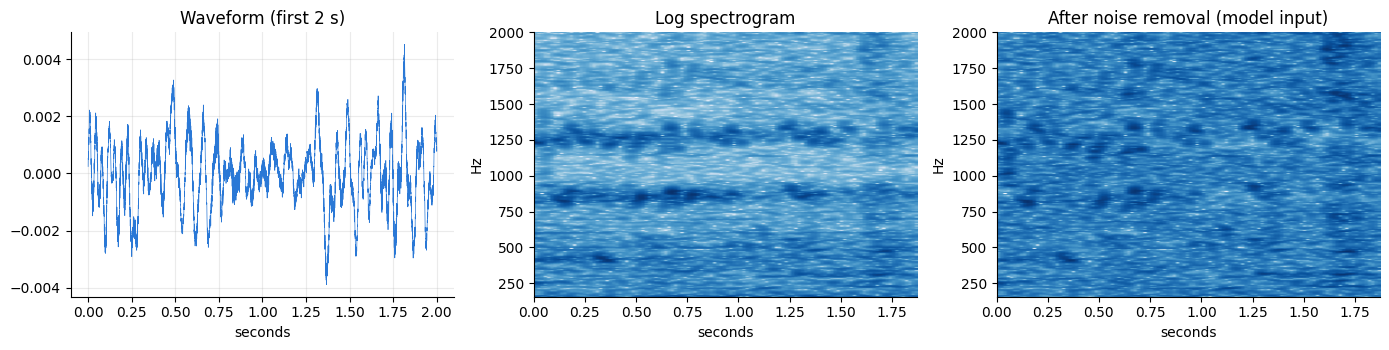

In [4]:
demo = ROOT / "demo" / "predict" / "demo_an_arabiensis.wav"
signal = load_audio(demo)
window = split_windows(signal)[0]
frames = np.lib.stride_tricks.sliding_window_view(window, N_FFT)[::HOP][: INPUT_SHAPE[1]]
plain = np.log(np.abs(np.fft.rfft(frames * HANN, axis=1)) ** 2 + 1e-10)[:, BAND].T
final = log_spectrogram(window)[..., 0]
freqs, seconds = FREQUENCIES[BAND], np.arange(INPUT_SHAPE[1]) * HOP / SAMPLE_RATE
print("Recording length:", round(signal.size / SAMPLE_RATE, 1), "s  windows:", len(split_windows(signal)))
print("Model input shape:", INPUT_SHAPE, " estimated wingbeat:", wingbeat_frequency(window), "Hz")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(np.arange(window.size) / SAMPLE_RATE, window, color="#2a78d6", linewidth=0.5)
axes[0].set(title="Waveform (first 2 s)", xlabel="seconds")
extent = [0, seconds[-1], freqs[0], freqs[-1]]
for axis, image, title in ((axes[1], plain, "Log spectrogram"), (axes[2], final, "After noise removal (model input)")):
    axis.imshow(image, origin="lower", aspect="auto", extent=extent, cmap="Blues")
    axis.set(title=title, xlabel="seconds", ylabel="Hz")
    axis.grid(False)
plt.tight_layout()
plt.show()

In the middle plot the dark horizontal lines near 420, 850 and 1250 Hz are the wingbeat tone and its harmonics. After the noise removal step (right), anything that stays the same for the full 2 seconds fades, including part of those lines and the background hiss. What is left is how the buzz changes over time, for example when the mosquito moves in the cup and the tone gets louder or shifts slightly. This version scored best on validation, which suggests the changing parts carry more species information than the steady parts, which also contain the noise of each recording night.

### Data augmentation

During training each spectrogram is randomly shifted in time and has a random band of frequencies and a random stretch of time blanked out (SpecAugment). This stops the model depending on one exact frequency row or moment.

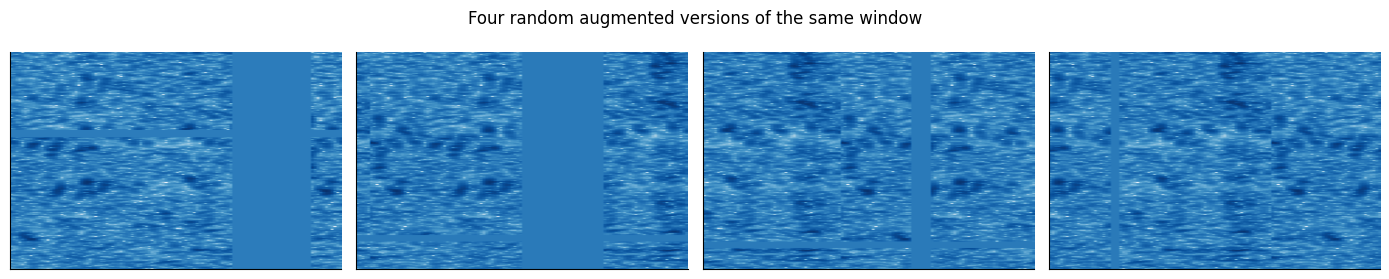

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for axis in axes:
    axis.imshow(augment(tf.constant(final[..., None])).numpy()[..., 0], origin="lower", aspect="auto", cmap="Blues")
    axis.set(xticks=[], yticks=[])
    axis.grid(False)
plt.suptitle("Four random augmented versions of the same window")
plt.tight_layout()
plt.show()

## 4. Feature interpretation: what story does the data tell?

`src/insights.py` measures three features on all 3,600 training clips. They are computed straight from the sound, not from the model. Energy below 150 Hz (mains and room hum) is ignored.

1. **Wingbeat frequency:** the pitch of the buzz, found with a harmonic product spectrum, which scores each candidate pitch by the energy at f, 2f and 3f together so a harmonic is not mistaken for the tone.
2. **Brightness:** the spectral centroid, the "centre of mass" of the sound.
3. **Tonal strength:** the share of energy that sits on the wingbeat and its first two harmonics.

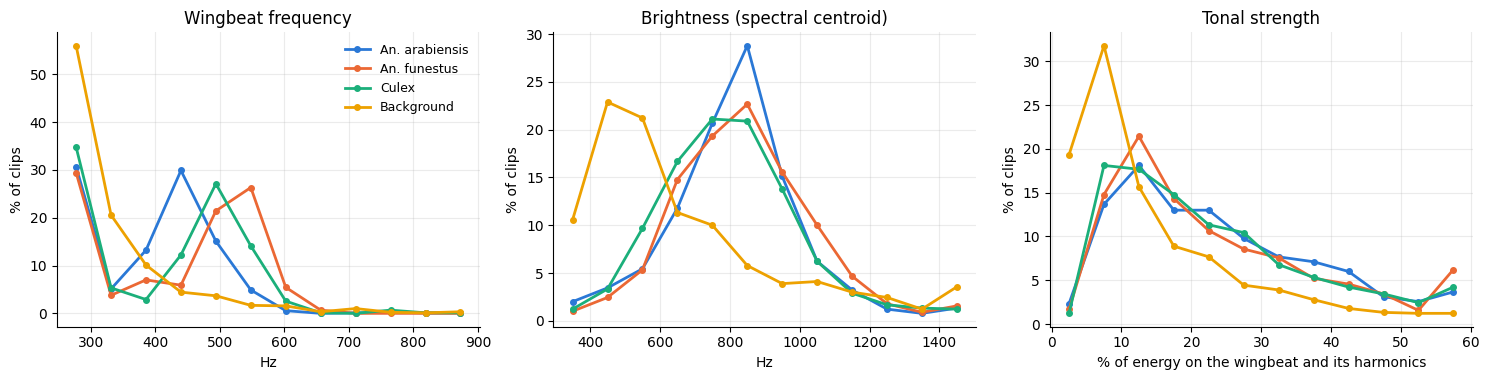

,Wingbeat frequency,Brightness (spectral centroid),Tonal strength
An. arabiensis,415.5,822.7,21.0
An. funestus,480.5,830.4,19.4
Culex,449.5,791.7,19.4
Background,301.0,572.0,9.7


In [6]:
insights = json.loads((MODELS / "insights.json").read_text())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for axis, feature in zip(axes, insights["features"].values()):
    edges = np.array(feature["edges"])
    centres = (edges[:-1] + edges[1:]) / 2
    for name in CLASSES:
        info = feature["classes"][name]
        axis.plot(centres, info["share_pct"], color=COLORS[name], linewidth=2, marker="o", markersize=4, label=NAMES[name])
    axis.set(title=feature["title"], xlabel=feature["unit"], ylabel="% of clips")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

medians = pd.DataFrame({feature["title"]: {NAMES[n]: feature["classes"][n]["median"] for n in CLASSES}
                        for feature in insights["features"].values()})
display(medians.round(1))

In [7]:
for feature in insights["features"].values():
    display(Markdown(f"**{feature['title']}.** {feature['story']}"))

**Wingbeat frequency.** The typical wingbeat tone is highest for An. funestus (480 Hz), then Culex (450 Hz), then An. arabiensis (416 Hz). The ranges overlap a lot, so pitch alone cannot name the species. The model also has to use the harmonics and how the sound changes over the 2 seconds, which is what the spectrogram CNN learns.

**Brightness (spectral centroid).** Mosquito clips are brighter, with a typical centre of 792 to 830 Hz, against 572 Hz for background noise. The three species are almost identical here, so brightness helps answer whether a mosquito is present, not which one.

**Tonal strength.** In a typical mosquito clip 19 to 21% of the energy sits on the wingbeat and its harmonics, about twice the 10% of background noise. A buzz is a clean tone with overtones, while room noise is spread out. Like brightness, it separates mosquito from no mosquito better than it separates species.

**What this means for the model.** Brightness and tonal strength split mosquito from background very clearly, and that matches the results below, where background is by far the easiest class. The three species are almost the same on all three features and only differ by about 30 to 60 Hz in typical wingbeat, with wide overlap. That is why the hard part of this problem is telling the species apart, and why the input needs fine frequency detail.

## 5. Model creation and optimization

A small CNN from scratch. Pre-trained image networks expect photos, and a spectrogram of a buzz has very different structure, so a compact network trained on this data is a better fit and also answers quickly on a CPU.

| Technique | Setting | Purpose |
|---|---|---|
| Three convolution blocks | 32, 64 and 128 filters, two 3x3 conv + batch norm each | Learn harmonic lines and how they move |
| Global average pooling | instead of a large dense layer | Fewer weights, less overfitting |
| Dropout | 0.3 | Regularisation |
| L2 weight decay | 1e-4 on conv and dense layers | Regularisation |
| Augmentation | time shift, frequency and time masks | More variety from the same clips |
| Optimizer | Adam, learning rate 1e-3 | Stable training |
| ReduceLROnPlateau | halves the rate when validation loss stalls | Finer steps near the end |
| Early stopping | patience 8 on validation loss, best weights kept | Stops before overfitting |
| Class weights | balanced | Kept for retraining, where uploads may be uneven |

In [8]:
build_model().summary()

Model: "wingbeat_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ spectrogram (InputLayer)        │ (None, 237, 118, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 237, 118, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 237, 118, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (ReLU)             │ (None, 237, 118, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 237, 118, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 237, 118, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (ReLU)             │ (None, 237, 118, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 118, 59, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 118, 59, 64)    │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 118, 59, 64)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (ReLU)             │ (None, 118, 59, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 118, 59, 64)    │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 118, 59, 64)    │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (ReLU)             │ (None, 118, 59, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 59, 29, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 59, 29, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 59, 29, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (ReLU)             │ (None, 59, 29, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 59, 29, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 59, 29, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (ReLU)             │ (None, 59, 29, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 29, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (GlobalAveragePooling2D)   │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 4)              │           51

 Total params: 288,292 (1.10 MB)

 Trainable params: 287,396 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

## 6. Model training

`RUN_FULL_TRAINING` is off by default because training both models takes over an hour on a laptop CPU. The cells load the saved models and the training history from the run done with `python -m src.train`, which uses exactly the functions imported above. Set it to `True` to train again.

### Baseline without optimization

The same network with no augmentation, no dropout and no L2. It still gets shuffled data and early stopping, so the comparison only measures what the optimization techniques add.

In [9]:
splits = {name: list_clips(DATA / name) for name in ("train", "validation", "test")}
if RUN_FULL_TRAINING:
    from src.train import main as train_both
    sys.argv = ["train"]
    train_both()
baseline = tf.keras.models.load_model(BASELINE_PATH)
model = tf.keras.models.load_model(MODEL_PATH)
baseline_saved = json.loads((MODELS / "baseline_metrics.json").read_text())
final_saved = json.loads((MODELS / "metrics.json").read_text())
histories = {"Baseline": baseline_saved["history"], "Optimized": json.loads((MODELS / "history.json").read_text())}
for name, history in histories.items():
    best = int(np.argmin(history["val_loss"]))
    print(f"{name}: {len(history['loss'])} epochs, best epoch {best + 1}, "
          f"train acc {history['accuracy'][best]:.3f}, validation acc {history['val_accuracy'][best]:.3f}")

Baseline: 17 epochs, best epoch 9, train acc 0.728, validation acc 0.520
Optimized: 37 epochs, best epoch 29, train acc 0.695, validation acc 0.615


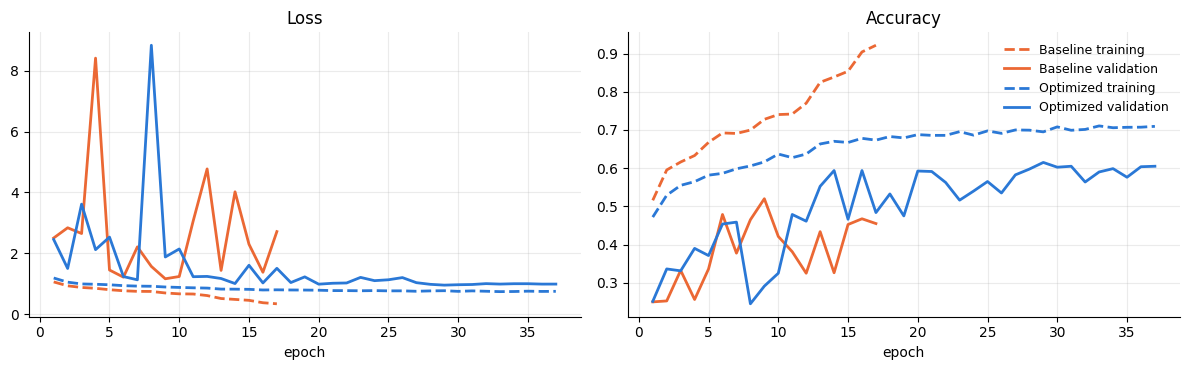

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for axis, key, title in ((axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")):
    for (name, history), color in zip(histories.items(), ("#eb6834", "#2a78d6")):
        epochs = np.arange(1, len(history[key]) + 1)
        axis.plot(epochs, history[key], color=color, linewidth=2, linestyle="--", label=f"{name} training")
        axis.plot(epochs, history["val_" + key], color=color, linewidth=2, label=f"{name} validation")
    axis.set(title=title, xlabel="epoch")
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

The baseline memorised the training clips: its training accuracy climbed past 0.9 while validation accuracy stayed under 0.53 and validation loss jumped around. The optimized model's training and validation curves stay much closer (about 0.70 against 0.61 at the best epoch), so augmentation, dropout and L2 did what they were meant to do. Both models have some unstable validation epochs early on. Each split holds only a few recording nights per class, so validation scores swing when the model leans on one night's sound.

## 7. Model evaluation

The final numbers come from the **test set**: nights the model never heard during training and that played no part in choosing the input or the settings.

In [11]:
results = {
    ("Baseline", "validation"): evaluate_model(baseline, *splits["validation"]),
    ("Baseline", "test"): evaluate_model(baseline, *splits["test"]),
    ("Optimized", "validation"): evaluate_model(model, *splits["validation"]),
    ("Optimized", "test"): evaluate_model(model, *splits["test"]),
}
LABELS = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
          "f1_macro": "F1 (macro)", "roc_auc_ovr": "ROC-AUC (one vs rest)", "cohen_kappa": "Cohen's kappa", "loss": "Loss"}
comparison = pd.DataFrame({f"{m} {s}": {LABELS[k]: r[k] for k in LABELS} for (m, s), r in results.items()})
display(comparison.round(3))
final_test = results[("Optimized", "test")]

,Baseline validation,Baseline test,Optimized validation,Optimized test
Accuracy,0.520,0.600,0.615,0.671
Precision (macro),0.538,0.670,0.593,0.675
Recall (macro),0.520,0.600,0.615,0.671
F1 (macro),0.473,0.561,0.595,0.667
ROC-AUC (one vs rest),0.800,0.873,0.830,0.884
Cohen's kappa,0.360,0.467,0.487,0.562
Loss,1.165,0.921,0.922,0.760


On the test set the optimized model is better on every metric: accuracy 0.671 against 0.600, macro F1 0.667 against 0.561, Cohen's kappa 0.562 against 0.467 and loss 0.760 against 0.921. The same is true on validation (accuracy 0.615 against 0.520). The biggest change is for *An. funestus*: the baseline recognised only 43 of 200 funestus test clips, mostly confusing them with *An. arabiensis* or background, while the optimized model got 117.

Test scores are higher than validation scores for both models. Because the split is by night, each split contains only 2 to 7 nights per class, and some nights are simply easier. So the exact numbers carry some uncertainty, and the comparison between the two models on the same clips is more reliable than any single number.

### Per-class results and confusion matrix

,precision,recall,f1,support
An. arabiensis,0.524,0.645,0.578,200
An. funestus,0.665,0.585,0.622,200
Culex,0.691,0.515,0.590,200
Background,0.821,0.940,0.876,200


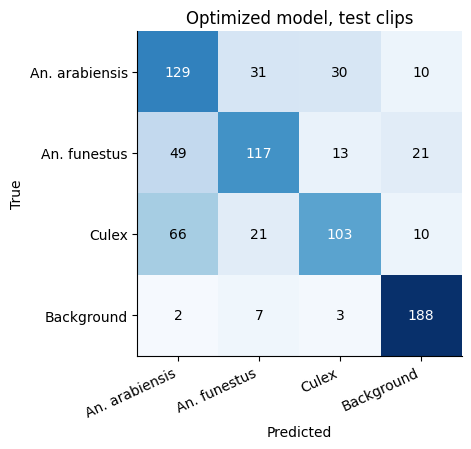

In [12]:
per_class = pd.DataFrame({NAMES[c]: final_test["per_class"][c] for c in CLASSES}).T
display(per_class.rename(columns={"f1-score": "f1"}).astype({"support": int}).round(3))

matrix = np.array(final_test["confusion_matrix"])
fig, axis = plt.subplots(figsize=(5.4, 4.6))
axis.imshow(matrix, cmap="Blues", vmin=0)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        axis.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ticks = [NAMES[c] for c in CLASSES]
axis.set(xticks=range(4), yticks=range(4), xticklabels=ticks, yticklabels=ticks, xlabel="Predicted", ylabel="True",
         title="Optimized model, test clips")
plt.setp(axis.get_xticklabels(), rotation=25, ha="right")
axis.grid(False)
plt.tight_layout()
plt.show()

**Interpretation.** Background is recognised best (recall 0.94, F1 0.876). Among the species, *An. funestus* has the best F1 (0.622) and *Culex* the lowest recall (0.515). *An. arabiensis* has the lowest precision (0.524) because the model uses it as a fallback: 49 funestus clips and 66 Culex clips were predicted as arabiensis. Very few mosquito clips are called background or the other way round, so most errors are species confusions, which fits the feature analysis above.

### Malaria vector or not

For a health worker the most useful question is often simpler than the species: is this a malaria vector? Here both *Anopheles* classes count as "vector" and Culex and background as "not a vector".

In [13]:
vector = np.array([c in ("an_arabiensis", "an_funestus") for c in CLASSES])
v = {"vector called vector": int(matrix[:2, :2].sum()), "vector missed": int(matrix[:2, 2:].sum()),
     "non-vector called vector": int(matrix[2:, :2].sum()), "non-vector called non-vector": int(matrix[2:, 2:].sum())}
print(v)
print("Vector accuracy:", round((v["vector called vector"] + v["non-vector called non-vector"]) / matrix.sum(), 3))
print("Vector recall:", round(v["vector called vector"] / (v["vector called vector"] + v["vector missed"]), 3))

{'vector called vector': 326, 'vector missed': 74, 'non-vector called vector': 96, 'non-vector called non-vector': 304}
Vector accuracy: 0.788
Vector recall: 0.815


The model flags 326 of 400 malaria vector clips (81.5%), but 96 of 400 non-vector clips are also called vectors, mostly Culex predicted as arabiensis. Overall it is right about vector or not on 78.8% of clips. For surveillance, a missed vector is worse than a false alarm, so this trade-off is acceptable, but it is not good enough to replace a microscope.

### Whole recordings

The API does not judge a single 2 s clip. It averages the predictions of every window in a recording. Grouping the test clips by recording gives the accuracy the API would get on these held-out recordings.

In [14]:
test_paths, test_labels = splits["test"]
probabilities = model.predict(make_dataset(test_paths, test_labels), verbose=0)
ids = [Path(p).stem.rsplit("_", 1)[0] for p in test_paths]
frame = pd.DataFrame(probabilities, columns=CLASSES).assign(recording=ids, label=test_labels)
by_recording = frame.groupby("recording").agg({**{c: "mean" for c in CLASSES}, "label": "first"})
recording_metrics = evaluate_probabilities(by_recording.label.values, by_recording[CLASSES].values)
print(f"{len(by_recording)} test recordings")
print({k: round(recording_metrics[k], 3) for k in ("accuracy", "f1_macro", "roc_auc_ovr")})

205 test recordings
{'accuracy': 0.741, 'f1_macro': 0.757, 'roc_auc_ovr': 0.897}


Averaging over all the windows in a recording raises accuracy from 0.671 per clip to 0.741 per recording (205 test recordings), with macro F1 0.757 and ROC-AUC 0.897. Single 2 s clips are noisy, and combining several of them cancels out some of the mistakes. This is why the API scores every window and averages them.

## 8. Model testing: prediction on a single recording

`src/prediction.py` is what the API calls. Here it runs on the four demo recordings in `demo/predict/`. They are held-out test recordings, cut to 10 seconds.

In [15]:
from src.prediction import Predictor

predictor = Predictor()
predictor.load()
rows = []
for name in CLASSES:
    result = predictor.predict(ROOT / "demo" / "predict" / f"demo_{name}.wav")
    rows.append({"file": f"demo_{name}.wav", "true": NAMES[name], "predicted": result["display_name"],
                 "confidence": result["confidence"], "malaria vector": result["malaria_vector"],
                 "windows agreeing": f"{result['window_labels'].count(result['label'])}/{result['windows']}",
                 "wingbeat Hz": result["wingbeat_hz"]})
display(pd.DataFrame(rows))

,file,true,predicted,confidence,malaria vector,windows agreeing,wingbeat Hz
0,demo_an_arabiensis.wav,An. arabiensis,Anopheles arabiensis,0.7488,True,5/5,425.0
1,demo_an_funestus.wav,An. funestus,Anopheles funestus,0.6617,True,5/5,320.0
2,demo_culex_pipiens.wav,Culex,Culex pipiens complex,0.8854,False,5/5,530.0
3,demo_background.wav,Background,No mosquito,0.9607,False,5/5,338.0


## 9. Retraining process

Retraining is in `src/retrain.py`. It is started with the **Retrain** button on the dashboard or `POST /retrain`, and can also start by itself once enough new recordings arrive (`AUTO_RETRAIN`, threshold `RETRAIN_AUTO_THRESHOLD`).

1. **Upload:** labelled recordings are uploaded in bulk, checked (format, length, not silent) and logged in a SQLite database.
2. **Preprocess:** each recording is cut into 2 s clips with the same code as above. Any file whose hash matches a validation or test clip is rejected, so the evaluation stays honest.
3. **Retrain:** the current model is loaded and trained further on the original training clips plus the new ones, at a lower learning rate (1e-4) with augmentation and early stopping.
4. **Compare and promote:** the new version is evaluated on the same validation and test sets. It replaces the live model only if it is at least as good, and the API reloads it without restarting.

## 10. Conclusion and limitations

The final model reached **0.671 accuracy, 0.667 macro F1 and 0.884 ROC-AUC on 800 test clips** from nights it never heard, and **0.741 accuracy on whole test recordings**. That is well above the 0.25 of guessing and above the unoptimized baseline on every metric. It almost never confuses a mosquito with background noise, and it flags 81.5% of malaria vector clips. Its main weakness is separating the three species, especially *Culex* from *An. arabiensis*.

Limitations:

- All recordings come from one study in Tanzania, made with mosquitoes in cups and one recorder model. A phone recording in a house would sound different, and the model would need retraining on such data.
- The test set for *An. arabiensis* comes from only 2 nights, so its scores could change a lot with different nights.
- Only female mosquitoes were used. Males beat their wings faster and were left out.
- *Culex* here is the *Culex pipiens* complex label from HumBugDB, which may itself contain more than one species.

The next steps would be more recording nights per species, recordings from phones, and a model that combines the spectrogram with the measured wingbeat frequency.